# Experimento de asimilacion con el Lorenz'96 de 40 variables

In [18]:
import sys;  sys.path.insert(0, '../src/')
import numpy as np
import numpy.linalg as la 
import dyn
import utils
import gra


## Defino la configuracion general

In [33]:
Ncy    = 1200 # numero de ciclos a asimilar
expdir = '../dat/l96_40v/001/' # directorio donde se guardan los resultados
Nx = 40     # numero de variables del estado  x
dtcy = 0.05 # longitud temporal ciclo 
Rfac = 0.5  # varianza del error observacional
Nem  = 100  # Numero de miembros del ensamble
Ny = 20     # Numero de observaciones
finf = 1.015 # factor de inflacion

m_kwargs = { 'Nx':Nx,'dtcy':dtcy,'expdir':expdir,'Nem':Nem }
o_kwargs = {'R':Rfac,'Nx':Nx,'Ny':Ny,
            'dat_fname':expdir+'trueobs',
            'obs_type':'uniform','Ncy':Ncy}
a_kwargs = { 'assmtd':'etkf','finf':finf}


## Modelo dinamico verdadero

In [25]:
Mdl    = dyn.L96(**m_kwargs)
xt0,X0 = Mdl.initialization()


Read sample file from: ../dat/l96_40v/001/ini_cond.npz


## Genero observaciones sinteticas

In [26]:
class OBS:
    """  Observaciones: 
            Se genera el operador observacional, el error observacional y las 
            observaciones sinteticas
            Linear observations: y = H x + noise"""

    def __init__(self, R=None, obs_indices=None, 
                 Nx=None, Ny=None, Ncy = 100,
                 dat_fname = None,
                 obs_type='uniform', seed=22):
        
        self.rng = np.random.default_rng(seed)
        self.randn = self.rng.standard_normal

        if obs_indices is None:
            obs_indices = utils.obs_points(Nx, Ny, mode=obs_type, rng=self.rng)
            
        self.obs_indices = np.atleast_1d(obs_indices)
        self.Ny = len(self.obs_indices)
        self.Ncy = Ncy

        self.H = np.eye(Nx)[self.obs_indices]       # (ny, nx) selection matrix
        R = np.asarray(R, dtype=float)
        if R.ndim == 0:                      # number -> R * I
            R = R * np.eye(self.Ny)
        self.R = R
        self.Rinv = la.inv(self.R)
        self.sqR = la.cholesky(self.R)       # R = sqR @ sqR.T

    def Hop(self, x):
        return self.H @ x

    def generate_obs(self, x0_true, Tmdl):
        ncy = self.Ncy
        nx = x0_true.shape[0]
        x = np.copy(x0_true)
        xt_t = np.empty((ncy, nx))
        y_t = np.empty((ncy, self.Ny))
        for it in range(ncy):
            xt_t[it] = x
            y_t[it] = self.H @ x + self.sqR @ self.randn(self.Ny)
            x = Tmdl.integ(x)
        return xt_t, y_t
    __call__ = generate_obs

Obs = OBS( **o_kwargs)
xt_t, y_t = Obs( xt0, Mdl )


[[file:../tmp/hovmoller.png]]


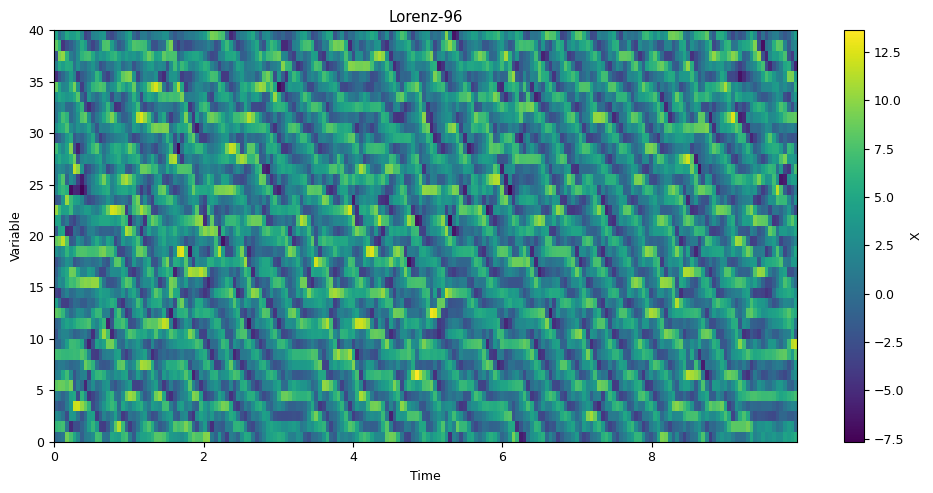

In [27]:
gra.plot_hovmoller(xt_t[1000:1500,:40],0.05,filename='../tmp/hovmoller.png')

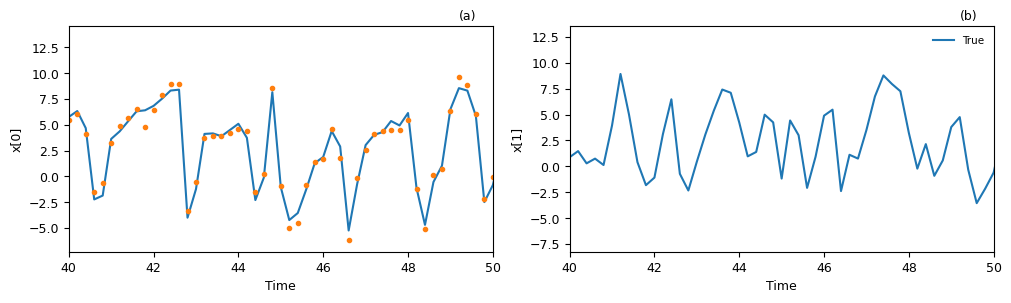

In [28]:
gra.plot_truth_obs(xt_t, y_t, Obs.obs_indices, dtcy, xlim=[40,50])

## Filtro de Kalman por ensambles

In [29]:
class FILTER:
    """ Filtro de Kalman por ensambles con dos variantes:
        Observaciones perturbadas  Burgers et al 1996
        ETKF  Hunt et al 2009
    """
    #- 1 -------------------------------------------------    
    def __init__(self, Fmdl,Obs,
                 assmtd='perobs',
                 finf = 1.0,
                 seed = 22,
                 ):
        
        self.assmtd = getattr(self, assmtd)    
        self.Hop    = Obs.Hop
        self.Obs    = Obs
        self.R, self.sqR = Obs.R, Obs.sqR
        self.Rinv   = Obs.Rinv      # etkf
        
        self.rng = np.random.default_rng(seed)
        self.randn = self.rng.standard_normal
        
        self.integ  = Fmdl.integ
        
        self.finf =finf
        
        
    #- 2 -------------------------------------------------
    def asscy(self,X0,y_t):
        """
            assimilation cyle.
            Observations are expected at it=1 (xa is at it=0)
        """

        [Nx, Nem] = X0.shape; [Ncy,Ny] = y_t.shape

        # variable initializations
        Xa_t,Xf_t=np.zeros((2,Ncy,Nx,Nem))

        Xa_t[0], Xf_t[0] = X0, X0 # a priori state at icy=0

        Xa=np.copy(X0)
        
        # next assimilation cycles
        for icy in range(1,Ncy,1):

            # Evolve forecast ensemble members
            Xf = self.integ(Xa)
            Xf_t[icy]=Xf # without inflation
            
            if np.isfinite(y_t[icy]).all(): # NaN observations do not exist    
               Xf = self.inflate(Xf)
               Xa = self.assmtd(Xf, y_t[icy])
            else: # if no obs, forecasts
                Xa=Xf
            
            Xa_t[icy]=Xa
            
        return Xa_t,Xf_t
    __call__=asscy

    #- 2 -------------------------------------------------
    def inflate(self, Xf):
        if self.finf > 1.0:
            xm = Xf.mean(1, keepdims=True)
            Xf = xm + self.finf * (Xf - xm)
        return Xf

    #- 2 -------------------------------------------------
    def perobs(self,Xf,y):
        """ Observaciones perturbadas  EnKF
             Evita calculo de la covarianza
             Usa diferencias del operador observacional 
                (suitable para nonlinear map)
             Xf [Nx,Nem],y [Ny]
             implicit: H, sqR, R
             \[ X^a = X^f + X'  [ \mathcal{H}'(x) ]
                 [ \mathcal{H}'(x)^\tau \mathcal{H}'(x) + R ]^{-1} 
                 ( y- \mathcal{H}(x) ) \]
        """
        
        Nem=Xf.shape[1]; Ny=y.shape[0]
        Hx = self.Hop(Xf) # # Observational map Ny,Nem
        
        xfm,Xper = utils.meanper(Xf)        
        hxm,Yper = utils.meanper(Hx)

        D = Yper @ Yper.T + self.R * (Nem-1)

        M = np.linalg.solve(D, Yper).T
        Noise = self.sqR @ self.randn( (Ny, Nem) )
        Xa = Xf + K @ (y[...,np.newaxis] - Hx + Noise)

        innov = y[:, None] - Hx + self.sqR @ self.randn((Ny, Nem))   # (Ny, Nem)
        
        #if Nem > 2 * Ny:                                     # large ensemble
        #    K = Xper @ M                                     # (Nx, Ny)
        #    return Xf + K @ innov
        #else:                                                # small ensemble
        return Xf + Xper @ (M @ innov)

    #- 3 -------------------------------------------------
    def etkf(self,Xf,yo):
        " Assimilate using Hunt et al, etkf, square root  enkf"
        
        Nem = Xf.shape[1]
        Rinv= self.Rinv
        
        Yf = self.Hop(Xf) # Observational map

        # mean and perturbations
        xfm,Xper = utils.meanper(Xf)        
        hxfm,Yper = utils.meanper(Yf)

        C = Yper.T @ Rinv
        B = (Nem-1.)*np.eye(Nem)+ C @ Yper

        Pa , Wa = utils.PaWa ( B ) # inverse and square root via EIG

        innov = yo[...,np.newaxis] - hxfm
        wa = Pa @ (C @ innov)

        Xa = xfm + Xper @ (wa+Wa)
        return Xa


In [30]:
Filter = FILTER(Mdl,Obs, **a_kwargs)

# Assimilate 
Xa_t, Xf_t = Filter(X0,y_t)

ispin = 200 # saco 200 ciclos para las estadisticas

rmse = utils.RMSE(xt_t[ispin:] - Xa_t[ispin:].mean(-1))

print('RMSE: ',rmse)


RMSE:  0.4653216268276454


## Resultados

[[file:../tmp/hovmoller.png]]


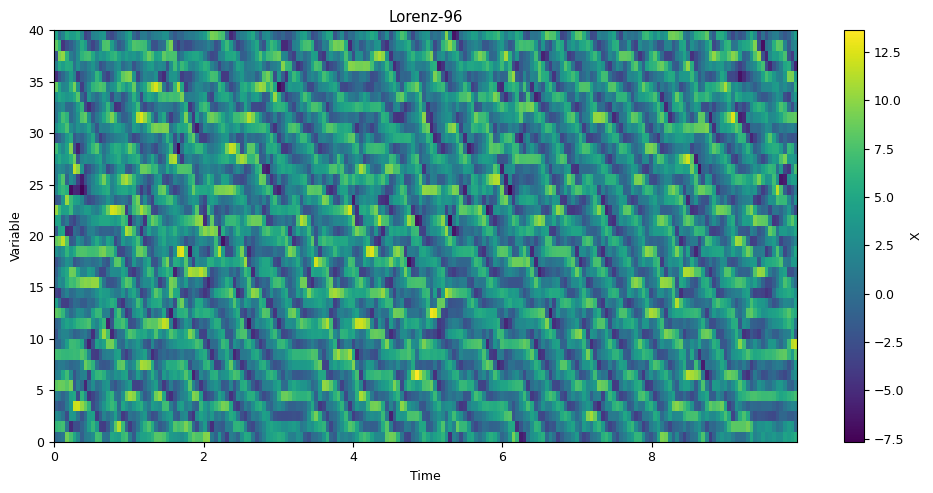

In [31]:
gra.plot_hovmoller(xt_t[1000:1500,:40],0.05,filename='../tmp/hovmoller.png')


[[file:../tmp/assm_L96.png]]


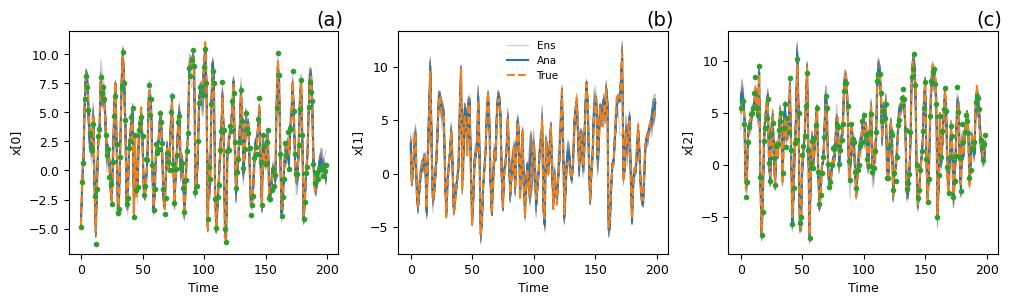

In [32]:
ini=800;end=1000
gra.assm([0,1,2],Xa_t[ini:end],y=y_t[ini:end], xt=xt_t[ini:end], indobs=Obs.obs_indices,
         filename='../tmp/assm_L96.png')
